# Exercício Programa Integrado — Análise Exploratória de Dados

**Disciplina:** Análise Exploratória de Dados (AED)
**Curso:** Análise e Desenvolvimento de Sistemas — Centro Universitário Impacta
**Professor:** Prof. Kyung Moo Kim
**Caso:** EduTech Impacta Solutions
**Grupo:** preencher os nomes antes da entrega

A base tem 250 alunos da plataforma de ensino. O arquivo nasce do script do enunciado, com semente 42, e traz de propósito valores ausentes, um erro de digitação e uma nota fora da escala. O notebook percorre o saneamento, a descrição univariada, a probabilidade, os testes de hipótese e a regressão. As conclusões para a gestão estão também no arquivo `Relatorio.md`.

Execute as células em ordem, de cima para baixo.

## Preparação

As figuras vão para a pasta `figuras/`. A base bruta, exatamente como o enunciado pede, fica em `dados/edutech_performance.csv`. A base usada nas análises, depois do saneamento, fica em `dados/edutech_performance_tratada.csv`. As colunas originais não são sobrescritas: o tratamento gera colunas novas, para ser possível auditar o que mudou.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import Markdown, display

PASTA_FIGURAS = Path("figuras")
PASTA_FIGURAS.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 150,
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
})

AZUL = "#1F4E79"
VERMELHO = "#A93226"
VERDE = "#1E8449"
PALETA_NIVEL = {"Extensão": "#5D6D7E", "Graduação": "#1F4E79", "Pós-Graduação": "#148F77"}
ORDEM_NIVEL = ["Extensão", "Graduação", "Pós-Graduação"]
ORDEM_CAMPUS = ["Barra Funda", "Paulista", "Alphaville", "EAD"]


def br(valor, casas=2):
    """Formata número no padrão brasileiro, para o texto interpretativo."""
    return f"{valor:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def salvar(fig, nome):
    caminho = PASTA_FIGURAS / nome
    fig.savefig(caminho, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return caminho

Matplotlib is building the font cache; this may take a moment.


## Geração da base oficial

O bloco abaixo é o script do enunciado, só reorganizado para ficar legível. A semente e a ordem dos sorteios não mudam: qualquer execução reproduz o mesmo `dados/edutech_performance.csv`.

In [2]:
np.random.seed(42)
n = 250

id_aluno = [f"EMP-{1000 + i}" for i in range(n)]
nivel_ensino = np.random.choice(
    ["Graduação", "Pós-Graduação", "Extensão"], size=n, p=[0.5, 0.3, 0.2]
)
regiao_campus = np.random.choice(
    ["Barra Funda", "Paulista", "Alphaville", "EAD"], size=n
)

horas_estudo = np.random.normal(loc=12, scale=4, size=n)
horas_estudo = np.clip(horas_estudo, 1, 30)

taxa_conclusao = 0.03 * horas_estudo + np.random.normal(loc=0.4, scale=0.15, size=n)
taxa_conclusao = np.clip(taxa_conclusao * 100, 10, 100)

nota_exame = (
    1.5
    + 0.25 * horas_estudo
    + 0.04 * taxa_conclusao
    + np.random.normal(loc=0, scale=0.8, size=n)
)
nota_exame = np.clip(nota_exame, 0.0, 10.0)
aprovado = np.where(nota_exame >= 6.0, "Sim", "Não")

df = pd.DataFrame({
    "id_aluno": id_aluno,
    "nivel_ensino": nivel_ensino,
    "regiao_campus": regiao_campus,
    "horas_estudo_semana": horas_estudo,
    "taxa_conclusao_pct": taxa_conclusao,
    "nota_exame_final": nota_exame,
    "aprovado": aprovado,
})

# Anomalias didáticas do enunciado. O 99 é gravado depois dos NaN,
# então a linha 5 fica com 99 mesmo que tivesse sido sorteada como ausente.
indices_ausentes = np.random.choice(df.index, 10)
df.loc[indices_ausentes, "horas_estudo_semana"] = np.nan
df.loc[5, "horas_estudo_semana"] = 99.0
df.loc[12, "nota_exame_final"] = -2.5

from pathlib import Path
Path("dados").mkdir(exist_ok=True)
df.to_csv("dados/edutech_performance.csv", index=False)

print(f"Registros: {len(df)}")
print("Ausentes por coluna:")
display(df.isna().sum().to_frame("ausentes"))
print("Horas iguais a 99:", int((df["horas_estudo_semana"] == 99).sum()))
print("Notas fora de [0, 10]:", int((~df["nota_exame_final"].between(0, 10)).sum()))
df.head()

Registros: 250
Ausentes por coluna:


,ausentes
id_aluno,0
nivel_ensino,0
regiao_campus,0
horas_estudo_semana,10
taxa_conclusao_pct,0
nota_exame_final,0
aprovado,0


Horas iguais a 99: 1
Notas fora de [0, 10]: 1


,id_aluno,nivel_ensino,regiao_campus,horas_estudo_semana,taxa_conclusao_pct,nota_exame_final,aprovado
0,EMP-1000,Graduação,Alphaville,15.539962,100.000000,9.715047,Sim
1,EMP-1001,Extensão,Barra Funda,NaN,82.000215,5.771731,Não
2,EMP-1002,Pós-Graduação,Barra Funda,9.511051,57.683068,5.664618,Não
3,EMP-1003,Pós-Graduação,EAD,10.578045,100.000000,8.979348,Sim
4,EMP-1004,Graduação,Alphaville,15.808044,60.870485,8.581043,Sim


## Módulo I — Organização, normalização e porcentagem

### 1.1 Saneamento

Três problemas aparecem na carga, e cada um pede uma decisão diferente.

1. **`horas_estudo_semana` tem 10 ausências.** Remover essas linhas jogaria fora 4% da amostra e enfraqueceria os testes seguintes. A média seria aceitável se a distribuição fosse simétrica e não houvesse erro grave na mesma coluna. Existe um 99 na mesma variável. Por isso a imputação usa a **mediana das horas válidas**, que não é arrastada por esse ponto. O 99 entra como ausência antes do cálculo da mediana. Se ele entrasse na conta, a mediana deixaria de ser um centro limpo.

2. **O valor 99 em `EMP-1005` é erro de digitação.** O gerador limita a carga semanal ao intervalo de 1 a 30 horas, e 99 horas equivalem a mais de 14 horas por dia. Não há como recuperar o número original a partir do arquivo. Tratar como ausente e imputar a mediana é mais honesto do que inventar 9,9.

3. **`taxa_conclusao_pct` está em percentual, de 0 a 100, e o roteiro pede a escala relativa decimal [0, 1].** Não há negativo nem valor acima de 100. A correção é dividir por 100. A coluna original permanece no arquivo para auditoria.

4. **A nota −2,5 de `EMP-1012` está fora da escala de 0 a 10.** O status `aprovado` foi gravado antes dessa corrupção e continua "Não", coerente com uma nota original abaixo de 6. A nota numérica é que ficou inutilizável. Ela sai das médias, dos gráficos de nota e da regressão. Não é imputada: imputar uma nota criaria um desempenho que ninguém observou.

A escolha da mediana, e não da remoção, preserva os 250 alunos nas análises que usam horas. O custo é conhecido: 11 horas imputadas (10 ausências mais o 99) puxam esses pontos para o centro e reduzem um pouco a variabilidade. No módulo de regressão essa escolha é comparada com a análise só dos casos completos.

In [3]:
perfil_bruto = pd.DataFrame({
    "minimo": df.min(numeric_only=True),
    "maximo": df.max(numeric_only=True),
    "ausentes": df.isna().sum(),
})
display(perfil_bruto)

horas_validas = df.loc[df["horas_estudo_semana"].between(1, 30), "horas_estudo_semana"]
mediana_horas = float(horas_validas.median())
media_horas_validas = float(horas_validas.mean())

df["hora_imputada"] = df["horas_estudo_semana"].isna() | (df["horas_estudo_semana"] > 30)
df["horas_estudo"] = df["horas_estudo_semana"].where(df["horas_estudo_semana"].between(1, 30))
df["horas_estudo"] = df["horas_estudo"].fillna(mediana_horas)

taxa_fora = ~df["taxa_conclusao_pct"].between(0, 100)
df["taxa_conclusao"] = df["taxa_conclusao_pct"] / 100

df["nota_invalida"] = ~df["nota_exame_final"].between(0, 10)
df["nota"] = df["nota_exame_final"].where(~df["nota_invalida"])

print(f"Mediana usada na imputação: {br(mediana_horas, 2)} h")
print(f"Média das horas válidas, só para comparação: {br(media_horas_validas, 2)} h")
print(f"Horas imputadas: {int(df['hora_imputada'].sum())} de {len(df)}")
print(f"Taxas fora de [0, 100] antes da normalização: {int(taxa_fora.sum())}")
print(f"Taxa na escala [0, 1]: mínimo {df['taxa_conclusao'].min():.3f}, máximo {df['taxa_conclusao'].max():.3f}")
print("Registros com nota inválida:")
display(df.loc[df["nota_invalida"], ["id_aluno", "nota_exame_final", "aprovado", "horas_estudo_semana"]])

,minimo,maximo,ausentes
aprovado,NaN,NaN,0
horas_estudo_semana,1.036181,99.0,10
id_aluno,NaN,NaN,0
nivel_ensino,NaN,NaN,0
nota_exame_final,-2.500000,10.0,0
regiao_campus,NaN,NaN,0
taxa_conclusao_pct,16.058205,100.0,0


Mediana usada na imputação: 11,94 h
Média das horas válidas, só para comparação: 12,07 h
Horas imputadas: 11 de 250
Taxas fora de [0, 100] antes da normalização: 0
Taxa na escala [0, 1]: mínimo 0.161, máximo 1.000
Registros com nota inválida:


,id_aluno,nota_exame_final,aprovado,horas_estudo_semana
12,EMP-1012,-2.5,Não,4.849314


### 1.2 Porcentagem e variação percentual

A base é ordenada pelo nível de ensino, na ordem Extensão, Graduação e Pós-Graduação, e pelo identificador. A variação pedida compara o tempo médio de estudo da Pós-Graduação com o da Graduação:

$$\Delta\% = \dfrac{\bar{x}_{pós} - \bar{x}_{grad}}{\bar{x}_{grad}} \times 100$$

A proporção de aprovados em cada campus é o número de "Sim" dividido pelo número de alunos daquele polo.

,alunos,media,mediana
nivel_ensino,,,
Extensão,53,12.239,12.217
Graduação,124,12.071,11.941
Pós-Graduação,73,11.931,11.252


A Pós-Graduação estuda -1,16% em relação à média da Graduação (11,93 h contra 12,07 h).


,alunos,aprovados,proporcao,percentual
regiao_campus,,,,
Barra Funda,60,46,0.767,76.667
Paulista,69,54,0.783,78.261
Alphaville,55,46,0.836,83.636
EAD,66,56,0.848,84.848


findfont: Failed to find font weight semibold for Arial, now using 700.


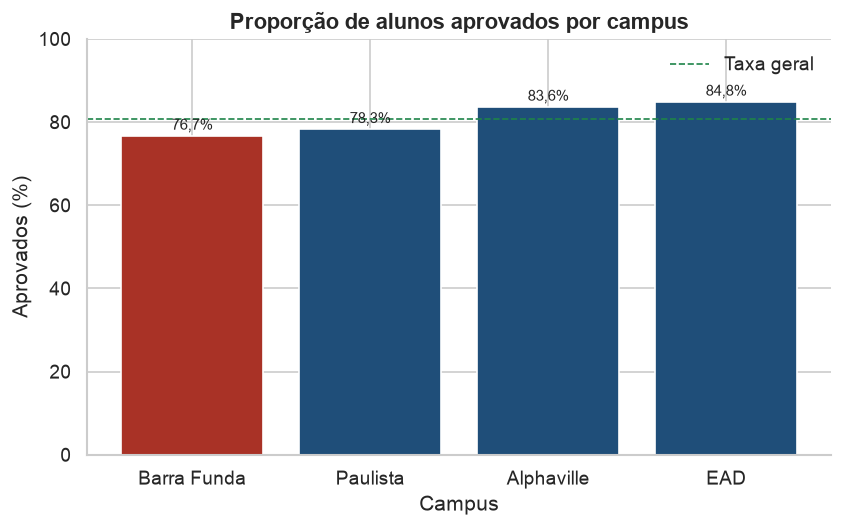

PosixPath('figuras/04_aprovacao_por_campus.png')

In [4]:
df["nivel_ensino"] = pd.Categorical(df["nivel_ensino"], categories=ORDEM_NIVEL, ordered=True)
df["regiao_campus"] = pd.Categorical(df["regiao_campus"], categories=ORDEM_CAMPUS, ordered=True)
df = df.sort_values(["nivel_ensino", "id_aluno"]).reset_index(drop=True)

horas_por_nivel = (
    df.groupby("nivel_ensino", observed=True)["horas_estudo"]
    .agg(alunos="count", media="mean", mediana="median")
)
media_grad = float(horas_por_nivel.loc["Graduação", "media"])
media_pos = float(horas_por_nivel.loc["Pós-Graduação", "media"])
variacao_pos_grad = (media_pos - media_grad) / media_grad * 100

display(horas_por_nivel.round(3))
print(
    f"A Pós-Graduação estuda {br(variacao_pos_grad, 2)}% em relação à média da Graduação "
    f"({br(media_pos, 2)} h contra {br(media_grad, 2)} h)."
)

aprovacao_campus = (
    df.groupby("regiao_campus", observed=True)
    .agg(
        alunos=("aprovado", "size"),
        aprovados=("aprovado", lambda s: int((s == "Sim").sum())),
    )
)
aprovacao_campus["proporcao"] = aprovacao_campus["aprovados"] / aprovacao_campus["alunos"]
aprovacao_campus["percentual"] = aprovacao_campus["proporcao"] * 100
display(aprovacao_campus.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
cores = [AZUL if campus != "Barra Funda" else VERMELHO for campus in aprovacao_campus.index.astype(str)]
barras = ax.bar(aprovacao_campus.index.astype(str), aprovacao_campus["percentual"], color=cores)
ax.set_ylim(0, 100)
ax.set_ylabel("Aprovados (%)")
ax.set_xlabel("Campus")
ax.set_title("Proporção de alunos aprovados por campus")
ax.axhline((df["aprovado"] == "Sim").mean() * 100, color=VERDE, ls="--", lw=1, label="Taxa geral")
for barra, pct in zip(barras, aprovacao_campus["percentual"]):
    ax.text(barra.get_x() + barra.get_width() / 2, pct + 1.5, f"{pct:.1f}%".replace(".", ","), ha="center", fontsize=9)
ax.legend(frameon=False)
sns.despine()
salvar(fig, "04_aprovacao_por_campus.png")

In [5]:
display(Markdown(
    f"""**Leitura do módulo I.** A diferença de carga horária entre Pós-Graduação e Graduação é de {br(variacao_pos_grad, 2)}%.
Em horas, isso é cerca de {br(abs(media_pos - media_grad) * 60, 0)} minutos por semana. Não há um grupo abandonando a plataforma.
A aprovação geral é de {br((df['aprovado'] == 'Sim').mean() * 100, 1)}%. Barra Funda tem a menor taxa
({br(aprovacao_campus.loc['Barra Funda', 'percentual'], 1)}%) e EAD a maior
({br(aprovacao_campus.loc['EAD', 'percentual'], 1)}%). A diferença ainda precisa passar por um teste, no módulo IV,
antes de virar decisão de polo."""
))

**Leitura do módulo I.** A diferença de carga horária entre Pós-Graduação e Graduação é de -1,16%.
Em horas, isso é cerca de 8 minutos por semana. Não há um grupo abandonando a plataforma.
A aprovação geral é de 80,8%. Barra Funda tem a menor taxa
(76,7%) e EAD a maior
(84,8%). A diferença ainda precisa passar por um teste, no módulo IV,
antes de virar decisão de polo.

## Módulo II — Análise exploratória univariada

### 2.1 Medidas de tendência central e dispersão

As medidas abaixo usam a nota na escala válida, de 0 a 10, sem o valor −2,5. Calcular a média com esse número trataria um erro de sistema como se fosse desempenho. A seção 2.2 mostra, com a conta, o que acontece se ele for mantido.

Definições usadas:

- média aparada a 5%: corte de 5% em cada cauda (`trim_mean` com `proportiontocut=0,05`);
- moda: a nota contínua quase não se repete, então a moda é calculada com uma casa decimal;
- coeficiente de variação: desvio padrão amostral dividido pela média;
- assimetria de Bowley: $(Q_3 + Q_1 - 2Q_2) / (Q_3 - Q_1)$;
- curtose: excesso de curtose de Fisher, em que a normal vale 0. A curtose de Pearson, em que a normal vale 3, aparece na mesma tabela.

In [6]:
def medidas(serie):
    x = pd.Series(serie).dropna()
    q1, q2, q3 = x.quantile([0.25, 0.5, 0.75])
    iqr = q3 - q1
    desvio = x.std(ddof=1)
    moda = x.round(1).mode()
    return pd.Series({
        "n": int(x.shape[0]),
        "media": x.mean(),
        "mediana": q2,
        "moda_1_decimal": float(moda.iloc[0]),
        "frequencia_da_moda": int((x.round(1) == moda.iloc[0]).sum()),
        "media_aparada_5pct": stats.trim_mean(x, 0.05),
        "variancia": x.var(ddof=1),
        "desvio_padrao": desvio,
        "amplitude": x.max() - x.min(),
        "minimo": x.min(),
        "maximo": x.max(),
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "cv": desvio / x.mean(),
        "assimetria_bowley": (q3 + q1 - 2 * q2) / iqr,
        "assimetria_momento": stats.skew(x, bias=False),
        "curtose_excesso": stats.kurtosis(x, fisher=True, bias=False),
        "curtose_pearson": stats.kurtosis(x, fisher=False, bias=False),
    })


nota = df["nota"].dropna()
nota_bruta = df["nota_exame_final"]
tabela_nota = medidas(nota).to_frame("nota saneada")
tabela_nota["nota bruta, com -2,5"] = medidas(nota_bruta)
display(tabela_nota.round(4))

q1, q2, q3 = nota.quantile([0.25, 0.5, 0.75])
bowley = (q3 + q1 - 2 * q2) / (q3 - q1)
print("Conta de Bowley na série saneada:")
print(f"  (Q3 + Q1 - 2*Q2) / (Q3 - Q1) = ({q3:.4f} + {q1:.4f} - 2*{q2:.4f}) / ({q3:.4f} - {q1:.4f}) = {bowley:.4f}")

,nota saneada,"nota bruta, com -2,5"
n,249.0000,250.0000
media,7.5156,7.4755
mediana,7.6346,7.6311
moda_1_decimal,10.0000,10.0000
frequencia_da_moda,15.0000,15.0000
media_aparada_5pct,7.5833,7.5690
variancia,2.6868,3.0773
desvio_padrao,1.6391,1.7542
amplitude,7.7464,12.5000
minimo,2.2536,-2.5000


Conta de Bowley na série saneada:
  (Q3 + Q1 - 2*Q2) / (Q3 - Q1) = (8.7543 + 6.4998 - 2*7.6346) / (8.7543 - 6.4998) = -0.0067


In [7]:
m = tabela_nota["nota saneada"]
display(Markdown(
    f"""**Leitura.** A nota média é {br(m['media'], 2)} e a mediana é {br(m['mediana'], 2)}.
A média aparada ({br(m['media_aparada_5pct'], 2)}) fica entre as duas, perto da média: o centro da distribuição não depende de meia dúzia de pontos extremos.
O coeficiente de variação é {br(m['cv'] * 100, 1)}%, dispersão moderada em torno de um desempenho alto.
Bowley deu {br(m['assimetria_bowley'], 3)}, praticamente zero: a caixa central é simétrica.
A assimetria pelo momento é {br(m['assimetria_momento'], 2)}, negativa, porque a cauda esquerda tem notas baixas de verdade e o teto 10 segura a cauda direita.
A moda em uma casa decimal é 10,0, com {int(m['frequencia_da_moda'])} alunos. Isso é efeito de teto da escala, não uma preferência pedagógica.
A curtose em excesso é {br(m['curtose_excesso'], 2)}, perto de zero, então o miolo não é mais pontudo nem mais achatado que uma normal. O teste formal de normalidade vem no módulo III, e a série completa não passa nele por causa desse teto."""
))

**Leitura.** A nota média é 7,52 e a mediana é 7,63.
A média aparada (7,58) fica entre as duas, perto da média: o centro da distribuição não depende de meia dúzia de pontos extremos.
O coeficiente de variação é 21,8%, dispersão moderada em torno de um desempenho alto.
Bowley deu -0,007, praticamente zero: a caixa central é simétrica.
A assimetria pelo momento é -0,53, negativa, porque a cauda esquerda tem notas baixas de verdade e o teto 10 segura a cauda direita.
A moda em uma casa decimal é 10,0, com 15 alunos. Isso é efeito de teto da escala, não uma preferência pedagógica.
A curtose em excesso é -0,20, perto de zero, então o miolo não é mais pontudo nem mais achatado que uma normal. O teste formal de normalidade vem no módulo III, e a série completa não passa nele por causa desse teto.

### 2.2 Sensibilidade a outliers

A média usa todos os valores com o mesmo peso. A mediana usa só a posição central. Um ponto impossível desloca a média e entra na soma de quadrados que produz o desvio padrão:

$$s = \sqrt{\dfrac{\sum_{i=1}^{n}(x_i - \bar{x})^2}{n - 1}}$$

O termo $(x^* - \bar{x})^2$ do ponto $x^* = -2{,}5$ é comparado com a soma de quadrados inteira. Em seguida a mesma conta é feita para a hora 99, que é o outro erro de digitação.

In [8]:
media_bruta = float(nota_bruta.mean())
media_sanea = float(nota.mean())
mediana_bruta = float(nota_bruta.median())
mediana_sanea = float(nota.median())
ss_bruta = float(((nota_bruta - media_bruta) ** 2).sum())
ss_sanea = float(((nota - media_sanea) ** 2).sum())
contrib_outlier = (-2.5 - media_bruta) ** 2
dp_bruto = float(nota_bruta.std(ddof=1))
dp_saneo = float(nota.std(ddof=1))

horas_com_99 = df["horas_estudo_semana"].dropna()
horas_sem_99 = horas_com_99[horas_com_99 <= 30]
dp_horas_com = float(horas_com_99.std(ddof=1))
dp_horas_sem = float(horas_sem_99.std(ddof=1))
z_99 = (99 - horas_sem_99.mean()) / horas_sem_99.std(ddof=1)

sensibilidade = pd.DataFrame({
    "com o erro": [media_bruta, mediana_bruta, media_bruta - mediana_bruta, dp_bruto, nota_bruta.var(ddof=1)],
    "sem o erro": [media_sanea, mediana_sanea, media_sanea - mediana_sanea, dp_saneo, nota.var(ddof=1)],
}, index=["média", "mediana", "média − mediana", "desvio padrão", "variância"])
display(sensibilidade.round(4))

print(f"Desvio do -2,5 em relação à média contaminada: {-2.5 - media_bruta:.4f}")
print(f"Quadrado desse desvio: {contrib_outlier:.4f}")
print(f"Soma de quadrados com o erro: {ss_bruta:.4f}")
print(f"Esse único ponto responde por {contrib_outlier / ss_bruta * 100:.1f}% da soma de quadrados.")
print(f"O desvio padrão sobe de {dp_saneo:.4f} para {dp_bruto:.4f}, um aumento de {(dp_bruto / dp_saneo - 1) * 100:.1f}%.")
print(f"A mediana quase não se mexe: {mediana_bruta:.4f} contra {mediana_sanea:.4f}.")
print()
print(f"Nas horas, o 99 fica a {z_99:.1f} desvios padrão da média válida.")
print(f"Desvio padrão das horas com o 99: {dp_horas_com:.3f}. Sem ele: {dp_horas_sem:.3f}.")
print(f"Inflação do desvio padrão das horas: {(dp_horas_com / dp_horas_sem - 1) * 100:.1f}%.")

,com o erro,sem o erro
média,7.4755,7.5156
mediana,7.6311,7.6346
média − mediana,-0.1556,-0.1190
desvio padrão,1.7542,1.6391
variância,3.0773,2.6868


Desvio do -2,5 em relação à média contaminada: -9.9755
Quadrado desse desvio: 99.5114
Soma de quadrados com o erro: 766.2391
Esse único ponto responde por 13.0% da soma de quadrados.
O desvio padrão sobe de 1.6391 para 1.7542, um aumento de 7.0%.
A mediana quase não se mexe: 7.6311 contra 7.6346.

Nas horas, o 99 fica a 21.1 desvios padrão da média válida.
Desvio padrão das horas com o 99: 6.959. Sem ele: 4.125.
Inflação do desvio padrão das horas: 68.7%.


In [9]:
display(Markdown(
    f"""**Leitura.** A média fica {br(media_bruta - media_sanea, 2)} ponto abaixo da média saneada quando o −2,5 entra.
A mediana muda na terceira casa decimal. Essa é a diferença prática entre as duas medidas: a média acredita no erro, a mediana não.
O estrago maior está no desvio padrão. O ponto −2,5 sozinho concentra {br(contrib_outlier / ss_bruta * 100, 1)}% da soma de quadrados
e aumenta o desvio padrão em {br((dp_bruto / dp_saneo - 1) * 100, 1)}%.
O 99 nas horas é ainda mais violento: um registro infla o desvio padrão da carga horária em {br((dp_horas_com / dp_horas_sem - 1) * 100, 0)}%.
Por isso as análises seguintes usam a série saneada. Um indicador de gestão calculado em cima do arquivo cru misturaria falha de cadastro com desempenho."""
))

**Leitura.** A média fica -0,04 ponto abaixo da média saneada quando o −2,5 entra.
A mediana muda na terceira casa decimal. Essa é a diferença prática entre as duas medidas: a média acredita no erro, a mediana não.
O estrago maior está no desvio padrão. O ponto −2,5 sozinho concentra 13,0% da soma de quadrados
e aumenta o desvio padrão em 7,0%.
O 99 nas horas é ainda mais violento: um registro infla o desvio padrão da carga horária em 69%.
Por isso as análises seguintes usam a série saneada. Um indicador de gestão calculado em cima do arquivo cru misturaria falha de cadastro com desempenho.

### 2.3 Visualização univariada

O histograma das horas usa a série já imputada, porque o 99 esmagaria a escala e esconderia o formato real. O boxplot da nota usa a série bruta de propósito: a regra do IQR precisa mostrar o −2,5 como atípico, e também separar esse erro dos atípicos que ainda são notas possíveis.

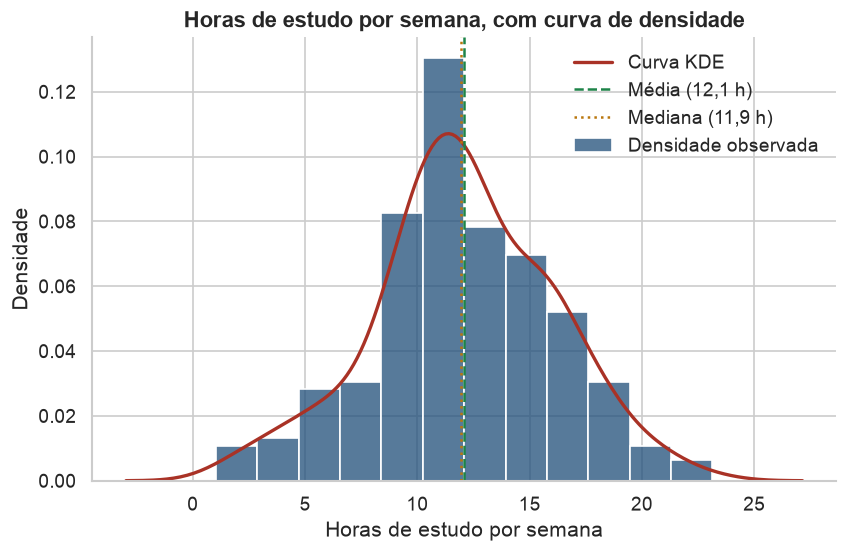

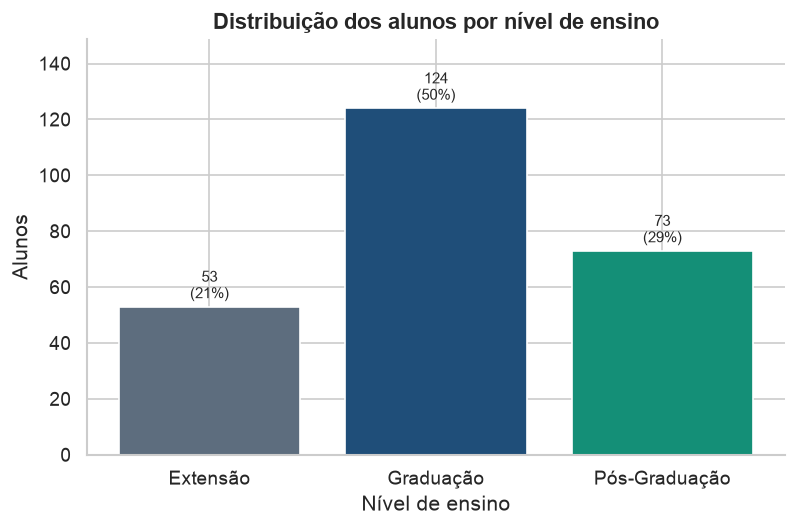

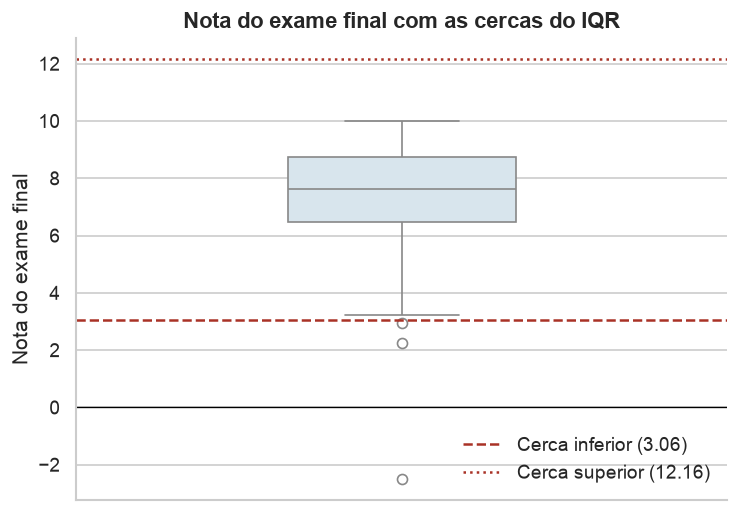

Q1 = 6.4712, Q3 = 8.7480, IQR = 2.2768
Cerca inferior = Q1 - 1,5*IQR = 3.0560
Cerca superior = Q3 + 1,5*IQR = 12.1633
Pontos fora das cercas:


,id_aluno,nota_exame_final,aprovado,regiao_campus
3,EMP-1012,-2.500000,Não,Alphaville
124,EMP-1135,2.945951,Não,Paulista
221,EMP-1163,2.253606,Não,Paulista


In [10]:
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.histplot(df["horas_estudo"], bins=12, stat="density", color=AZUL, edgecolor="white", ax=ax, label="Densidade observada")
sns.kdeplot(df["horas_estudo"], color=VERMELHO, lw=2, ax=ax, label="Curva KDE")
ax.axvline(df["horas_estudo"].mean(), color=VERDE, ls="--", label=f"Média ({br(df['horas_estudo'].mean(), 1)} h)")
ax.axvline(df["horas_estudo"].median(), color="#B9770E", ls=":", label=f"Mediana ({br(df['horas_estudo'].median(), 1)} h)")
ax.set_xlabel("Horas de estudo por semana")
ax.set_ylabel("Densidade")
ax.set_title("Horas de estudo por semana, com curva de densidade")
ax.legend(frameon=False)
sns.despine()
salvar(fig, "01_histograma_horas.png")

contagem_nivel = df["nivel_ensino"].value_counts().reindex(ORDEM_NIVEL)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
barras = ax.bar(
    contagem_nivel.index.astype(str),
    contagem_nivel.values,
    color=[PALETA_NIVEL[nivel] for nivel in contagem_nivel.index.astype(str)],
)
ax.set_ylabel("Alunos")
ax.set_xlabel("Nível de ensino")
ax.set_title("Distribuição dos alunos por nível de ensino")
for barra, valor in zip(barras, contagem_nivel.values):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 1.5,
        f"{valor}\n({valor / len(df) * 100:.0f}%)",
        ha="center",
        va="bottom",
        fontsize=9,
    )
ax.set_ylim(0, contagem_nivel.max() * 1.2)
sns.despine()
salvar(fig, "02_barras_nivel_ensino.png")

q1_b, q3_b = nota_bruta.quantile([0.25, 0.75])
iqr_b = q3_b - q1_b
cerca_inf = q1_b - 1.5 * iqr_b
cerca_sup = q3_b + 1.5 * iqr_b
atipicos = nota_bruta[(nota_bruta < cerca_inf) | (nota_bruta > cerca_sup)]

fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(y=nota_bruta, color="#D4E6F1", width=0.35, ax=ax)
ax.axhline(cerca_inf, color=VERMELHO, ls="--", label=f"Cerca inferior ({cerca_inf:.2f})")
ax.axhline(cerca_sup, color=VERMELHO, ls=":", label=f"Cerca superior ({cerca_sup:.2f})")
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Nota do exame final")
ax.set_title("Nota do exame final com as cercas do IQR")
ax.legend(frameon=False, loc="lower right")
sns.despine()
salvar(fig, "03_boxplot_nota.png")

print(f"Q1 = {q1_b:.4f}, Q3 = {q3_b:.4f}, IQR = {iqr_b:.4f}")
print(f"Cerca inferior = Q1 - 1,5*IQR = {cerca_inf:.4f}")
print(f"Cerca superior = Q3 + 1,5*IQR = {cerca_sup:.4f}")
print("Pontos fora das cercas:")
display(df.loc[atipicos.index, ["id_aluno", "nota_exame_final", "aprovado", "regiao_campus"]])

In [11]:
display(Markdown(
    f"""**Leitura dos gráficos.** As horas, depois do saneamento, se concentram em torno de {br(df['horas_estudo'].median(), 1)} h semanais.
Média e mediana quase coincidem e a curva KDE não mostra um segundo pico. A carga de estudo é um bloco só, não dois públicos escondidos.
Graduação é metade da base ({contagem_nivel['Graduação']} alunos, {br(contagem_nivel['Graduação'] / len(df) * 100, 0)}%), seguida de Pós-Graduação e Extensão.
No boxplot, as cercas são {br(cerca_inf, 2)} e {br(cerca_sup, 2)}. Três pontos ficam abaixo da cerca inferior.
O −2,5 é erro de escala. Os outros dois são notas baixas, porém dentro de 0 a 10: são alunos com dificuldade, não falha de cadastro.
A cerca superior passa de 10, então ninguém é marcado como atípico por tirar nota alta. A escala corta antes."""
))

**Leitura dos gráficos.** As horas, depois do saneamento, se concentram em torno de 11,9 h semanais.
Média e mediana quase coincidem e a curva KDE não mostra um segundo pico. A carga de estudo é um bloco só, não dois públicos escondidos.
Graduação é metade da base (124 alunos, 50%), seguida de Pós-Graduação e Extensão.
No boxplot, as cercas são 3,06 e 12,16. Três pontos ficam abaixo da cerca inferior.
O −2,5 é erro de escala. Os outros dois são notas baixas, porém dentro de 0 a 10: são alunos com dificuldade, não falha de cadastro.
A cerca superior passa de 10, então ninguém é marcado como atípico por tirar nota alta. A escala corta antes.

## Módulo III — Probabilidade e simulações

### 3.1 Probabilidade condicional e Bayes

$A$ é o evento "aprovado" e $B$ é o evento "estar na Pós-Graduação". O roteiro pede $P(A \mid B)$ pelo teorema de Bayes:

$$P(A \mid B) = \dfrac{P(B \mid A)\,P(A)}{P(B)}$$

A conta é conferida pela definição direta, $P(A \mid B) = n(A \cap B) / n(B)$. As duas têm de coincidir. Aqui a probabilidade é a frequência na própria base, que funciona como a taxa histórica disponível.

In [12]:
n_total = len(df)
n_aprov = int((df["aprovado"] == "Sim").sum())
n_pos = int((df["nivel_ensino"] == "Pós-Graduação").sum())
n_pos_e_aprov = int(((df["nivel_ensino"] == "Pós-Graduação") & (df["aprovado"] == "Sim")).sum())

p_aprov = n_aprov / n_total
p_pos = n_pos / n_total
p_pos_dado_aprov = n_pos_e_aprov / n_aprov
p_aprov_dado_pos = p_pos_dado_aprov * p_aprov / p_pos
p_aprov_dado_pos_direto = n_pos_e_aprov / n_pos

print(f"P(Aprovado) = {n_aprov}/{n_total} = {p_aprov:.6f}")
print(f"P(Pós-Graduação) = {n_pos}/{n_total} = {p_pos:.6f}")
print(f"P(Pós | Aprovado) = {n_pos_e_aprov}/{n_aprov} = {p_pos_dado_aprov:.6f}")
print(f"Bayes: P(Aprovado | Pós) = {p_pos_dado_aprov:.6f} * {p_aprov:.6f} / {p_pos:.6f} = {p_aprov_dado_pos:.6f}")
print(f"Conferência direta: {n_pos_e_aprov}/{n_pos} = {p_aprov_dado_pos_direto:.6f}")

taxas_nivel = df.groupby("nivel_ensino", observed=True)["aprovado"].apply(lambda s: (s == "Sim").mean())
display((taxas_nivel * 100).round(1).to_frame("aprovação (%)"))

P(Aprovado) = 202/250 = 0.808000
P(Pós-Graduação) = 73/250 = 0.292000
P(Pós | Aprovado) = 61/202 = 0.301980
Bayes: P(Aprovado | Pós) = 0.301980 * 0.808000 / 0.292000 = 0.835616
Conferência direta: 61/73 = 0.835616


,aprovação (%)
nivel_ensino,
Extensão,86.8
Graduação,76.6
Pós-Graduação,83.6


### 3.2 Distribuição binomial

Numa amostra aleatória de 10 alunos, $X \sim B(10, p)$, com $p = P(Aprovado)$ estimado na base. A probabilidade de exatamente 7 aprovações é

$$P(X = 7) = \binom{10}{7} p^{7} (1 - p)^{3}$$

O $p$ foi estimado nesta amostra. O resultado é a probabilidade condicional a essa taxa, não uma probabilidade com $p$ conhecido de antemão.

In [13]:
from math import comb

p = p_aprov
k, n_bin = 7, 10
prob_manual = comb(n_bin, k) * (p ** k) * ((1 - p) ** (n_bin - k))
prob_scipy = float(stats.binom.pmf(k, n_bin, p))
mais_provavel = int(stats.binom.pmf(np.arange(0, 11), n_bin, p).argmax())

print(f"C(10, 7) = {comb(10, 7)}")
print(f"P(X = 7) pela fórmula = {prob_manual:.6f}")
print(f"P(X = 7) pelo SciPy   = {prob_scipy:.6f}")
print(f"Valor mais provável em B(10, {p:.3f}): {mais_provavel} aprovados")
print(f"P(X = {mais_provavel}) = {stats.binom.pmf(mais_provavel, n_bin, p):.6f}")

C(10, 7) = 120
P(X = 7) pela fórmula = 0.190970
P(X = 7) pelo SciPy   = 0.190970
Valor mais provável em B(10, 0.808): 8 aprovados
P(X = 8) = 0.301374


### 3.3 Distribuição normal

Assume-se $nota \sim N(\mu, \sigma^2)$, com $\mu$ e $\sigma$ estimados na série saneada. O escore padronizado da nota 8,5 é

$$Z = \dfrac{8{,}5 - \hat\mu}{\hat\sigma}, \qquad P(X > 8{,}5) = 1 - \Phi(Z)$$

Como $\sigma$ populacional não é conhecido, entra o desvio padrão amostral. A probabilidade é uma aproximação plug-in. A série tem teto em 10, então a normal é uma referência, não uma descrição fiel. A frequência observada de notas acima de 8,5 entra ao lado para mostrar o tamanho do desvio.

In [14]:
mu = float(nota.mean())
sigma = float(nota.std(ddof=1))
z_85 = (8.5 - mu) / sigma
p_acima_85 = float(stats.norm.sf(z_85))
p_empirica_85 = float((nota > 8.5).mean())
shapiro_nota = stats.shapiro(nota)

print(f"mu = {mu:.4f}, sigma = {sigma:.4f}")
print(f"Z = (8.5 - {mu:.4f}) / {sigma:.4f} = {z_85:.4f}")
print(f"P(X > 8.5) sob a normal = {p_acima_85:.4f}")
print(f"Frequência observada de notas > 8,5 = {p_empirica_85:.4f} ({int((nota > 8.5).sum())} de {len(nota)})")
print(f"Shapiro-Wilk na nota saneada: W = {shapiro_nota.statistic:.4f}, p = {shapiro_nota.pvalue:.4g}")

mu = 7.5156, sigma = 1.6391
Z = (8.5 - 7.5156) / 1.6391 = 0.6006
P(X > 8.5) sob a normal = 0.2741
Frequência observada de notas > 8,5 = 0.3213 (80 de 249)
Shapiro-Wilk na nota saneada: W = 0.9682, p = 2.41e-05


In [15]:
display(Markdown(
    f"""**Leitura do módulo III.** A chance histórica de aprovação é {br(p_aprov * 100, 1)}% ({n_aprov} de {n_total}).
Entre os alunos de Pós-Graduação essa chance sobe para {br(p_aprov_dado_pos * 100, 1)}% ({n_pos_e_aprov} de {n_pos}).
Bayes e a contagem direta dão o mesmo número, como tinham de dar: o teorema reorganiza a informação, não cria outra probabilidade.
Num grupo aleatório de 10 alunos, a probabilidade de sair exatamente 7 aprovados é {br(prob_scipy * 100, 1)}%.
O resultado mais comum nesse grupo seria {mais_provavel} aprovados, porque a taxa histórica está perto de 80%.
Pela normal, cerca de {br(p_acima_85 * 100, 1)}% tirariam nota acima de 8,5. Na base, essa fatia é {br(p_empirica_85 * 100, 1)}%.
A normal subestima o topo porque {int((nota == 10).sum())} alunos estão empilhados na nota 10 e o teste de Shapiro-Wilk rejeita a normalidade da nota (p = {shapiro_nota.pvalue:.4g}).
O número teórico responde ao roteiro; a gestão deve citar a frequência observada quando falar de excelência."""
))

**Leitura do módulo III.** A chance histórica de aprovação é 80,8% (202 de 250).
Entre os alunos de Pós-Graduação essa chance sobe para 83,6% (61 de 73).
Bayes e a contagem direta dão o mesmo número, como tinham de dar: o teorema reorganiza a informação, não cria outra probabilidade.
Num grupo aleatório de 10 alunos, a probabilidade de sair exatamente 7 aprovados é 19,1%.
O resultado mais comum nesse grupo seria 8 aprovados, porque a taxa histórica está perto de 80%.
Pela normal, cerca de 27,4% tirariam nota acima de 8,5. Na base, essa fatia é 32,1%.
A normal subestima o topo porque 15 alunos estão empilhados na nota 10 e o teste de Shapiro-Wilk rejeita a normalidade da nota (p = 2.41e-05).
O número teórico responde ao roteiro; a gestão deve citar a frequência observada quando falar de excelência.

## Módulo IV — Análise bivariada e testes de hipóteses

O nível de significância é 5% em todos os testes. Não rejeitar $H_0$ não prova igualdade. Prova apenas que esta amostra não sustentou a diferença alegada.

### 4.1 Nível de ensino e aprovação

$H_0$: nível de ensino e aprovação são independentes.
$H_1$: há associação.
O qui-quadrado de independência usa a tabela cruzada. O V de Cramer mede o tamanho do efeito:

$$V = \sqrt{\dfrac{\chi^2}{n \cdot \min(r - 1,\, c - 1)}}$$

Valores perto de 0,1 são associação fraca. Isso é uma régua convencional, não um corte da teoria.

In [16]:
tabela = pd.crosstab(df["nivel_ensino"], df["aprovado"])
display(tabela)
qui2, p_qui, gl, esperadas = stats.chi2_contingency(tabela)
n_qui = int(tabela.to_numpy().sum())
v_cramer = np.sqrt(qui2 / (n_qui * min(tabela.shape[0] - 1, tabela.shape[1] - 1)))
qui2_critico = float(stats.chi2.ppf(0.95, gl))

print("Frequências esperadas sob independência:")
display(pd.DataFrame(esperadas, index=tabela.index, columns=tabela.columns).round(2))
print(f"chi2 = {qui2:.4f}, gl = {gl}, valor crítico a 5% = {qui2_critico:.4f}, p = {p_qui:.4f}")
print(f"V de Cramer = {v_cramer:.4f}")
print("Menor frequência esperada:", round(esperadas.min(), 2))
print("Decisão: não rejeitar H0." if p_qui > 0.05 else "Decisão: rejeitar H0.")

aprovado,Não,Sim
nivel_ensino,,
Extensão,7,46
Graduação,29,95
Pós-Graduação,12,61


Frequências esperadas sob independência:


aprovado,Não,Sim
nivel_ensino,,
Extensão,10.18,42.82
Graduação,23.81,100.19
Pós-Graduação,14.02,58.98


chi2 = 2.9870, gl = 2, valor crítico a 5% = 5.9915, p = 0.2246
V de Cramer = 0.1093
Menor frequência esperada: 10.18
Decisão: não rejeitar H0.


### 4.2 Campus e nota

Os boxplots paralelos comparam a nota válida entre os quatro polos. O teste t de Student para amostras independentes compara Barra Funda e EAD, como o roteiro pede.

$H_0$: $\mu_{Barra\ Funda} = \mu_{EAD}$.
$H_1$: as médias diferem.

Antes do teste t, Levene verifica se as variâncias podem ser tratadas como iguais. Shapiro-Wilk verifica a normalidade em cada grupo. Com dezenas de observações o teste t aguenta um afastamento moderado da normal, mas a checagem fica registrada. O teste de Mann-Whitney entra como conferência, sem substituir o teste pedido.

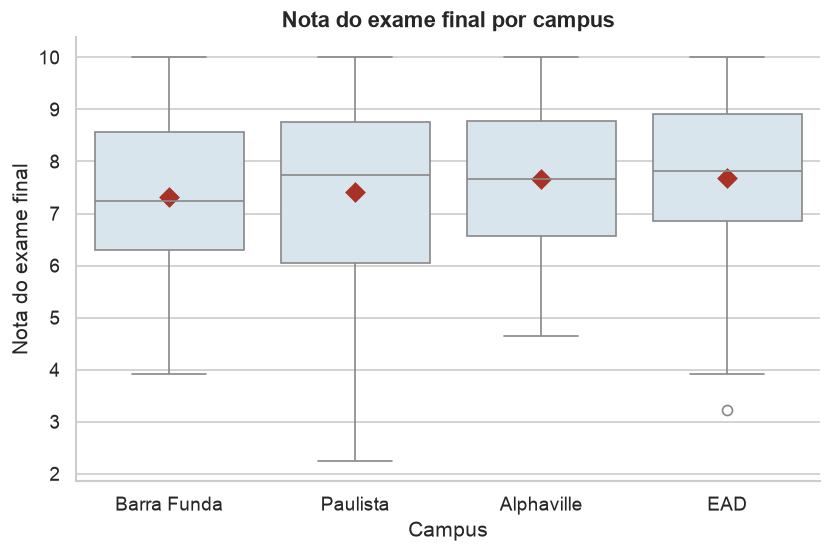

,count,mean,std,median
regiao_campus,,,,
Barra Funda,60,7.321,1.561,7.239
Paulista,69,7.412,1.882,7.741
Alphaville,54,7.662,1.462,7.671
EAD,66,7.681,1.581,7.821


Barra Funda: n = 60, média = 7.321, dp = 1.561
EAD:         n = 66, média = 7.681, dp = 1.581
Levene: estatística = 0.133, p = 0.716
Shapiro Barra Funda: p = 0.325
Shapiro EAD: p = 0.013
t de Student = -1.286, gl = 124, crítico = ±1.979, p = 0.201
t de Welch (conferência) = -1.287, p = 0.200
Mann-Whitney (conferência) = 1685, p = 0.150


In [17]:
nota_campus = df.loc[~df["nota_invalida"], ["regiao_campus", "nota"]]

fig, ax = plt.subplots(figsize=(8, 4.8))
sns.boxplot(data=nota_campus, x="regiao_campus", y="nota", order=ORDEM_CAMPUS, color="#D4E6F1", ax=ax)
sns.pointplot(
    data=nota_campus, x="regiao_campus", y="nota", order=ORDEM_CAMPUS,
    color=VERMELHO, markers="D", linestyle="none", errorbar=None, ax=ax,
)
ax.set_xlabel("Campus")
ax.set_ylabel("Nota do exame final")
ax.set_title("Nota do exame final por campus")
sns.despine()
salvar(fig, "05_boxplot_nota_campus.png")

bf = nota_campus.loc[nota_campus["regiao_campus"] == "Barra Funda", "nota"]
ead = nota_campus.loc[nota_campus["regiao_campus"] == "EAD", "nota"]
levene = stats.levene(bf, ead)
shapiro_bf = stats.shapiro(bf)
shapiro_ead = stats.shapiro(ead)
tteste = stats.ttest_ind(bf, ead, equal_var=True)
welch = stats.ttest_ind(bf, ead, equal_var=False)
mann = stats.mannwhitneyu(bf, ead, alternative="two-sided")
t_critico = float(stats.t.ppf(0.975, tteste.df))

resumo_campus = nota_campus.groupby("regiao_campus", observed=True)["nota"].agg(["count", "mean", "std", "median"])
display(resumo_campus.round(3))
print(f"Barra Funda: n = {len(bf)}, média = {bf.mean():.3f}, dp = {bf.std(ddof=1):.3f}")
print(f"EAD:         n = {len(ead)}, média = {ead.mean():.3f}, dp = {ead.std(ddof=1):.3f}")
print(f"Levene: estatística = {levene.statistic:.3f}, p = {levene.pvalue:.3f}")
print(f"Shapiro Barra Funda: p = {shapiro_bf.pvalue:.3f}")
print(f"Shapiro EAD: p = {shapiro_ead.pvalue:.3f}")
print(f"t de Student = {tteste.statistic:.3f}, gl = {tteste.df:.0f}, crítico = ±{t_critico:.3f}, p = {tteste.pvalue:.3f}")
print(f"t de Welch (conferência) = {welch.statistic:.3f}, p = {welch.pvalue:.3f}")
print(f"Mann-Whitney (conferência) = {mann.statistic:.0f}, p = {mann.pvalue:.3f}")

### 4.3 Horas de estudo e nota

O gráfico de dispersão cruza a hora saneada com a nota válida. Pearson mede a associação linear. Spearman mede a associação monotônica e sofre menos com um ponto estranho ou com uma curva leve.

Correlação não é causalidade. Horas e nota andam juntas nesta base. Isso não autoriza a gestão a prometer que obrigar o aluno a estudar mais horas produz, sozinho, o ganho da reta. Motivação, base anterior e dificuldade do curso podem empurrar as duas variáveis. O módulo V separa pelo menos um desses canais, a taxa de conclusão, que também sobe com as horas.

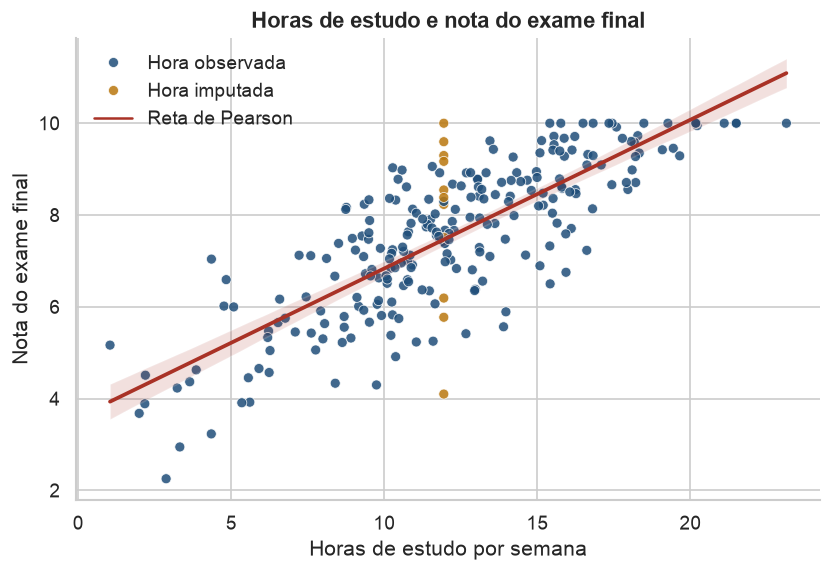

Pearson r = 0.7934, p = 3.635e-55
Spearman rho = 0.7741, p = 5.987e-51
Pearson entre taxa de conclusão e nota: r = 0.7675
Pearson entre horas e taxa de conclusão: r = 0.5995


In [18]:
dispersao = df.loc[~df["nota_invalida"], ["horas_estudo", "nota", "taxa_conclusao", "hora_imputada"]].copy()
pearson = stats.pearsonr(dispersao["horas_estudo"], dispersao["nota"])
spearman = stats.spearmanr(dispersao["horas_estudo"], dispersao["nota"])
pearson_taxa = stats.pearsonr(dispersao["taxa_conclusao"], dispersao["nota"])
pearson_horas_taxa = stats.pearsonr(dispersao["horas_estudo"], dispersao["taxa_conclusao"])

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
    data=dispersao, x="horas_estudo", y="nota",
    hue="hora_imputada", palette={False: AZUL, True: "#B9770E"},
    ax=ax, alpha=0.85, s=36,
)
ax.plot([], [], color=VERMELHO, label="Reta de Pearson")
sns.regplot(
    data=dispersao, x="horas_estudo", y="nota",
    scatter=False, color=VERMELHO, ax=ax,
)
ax.set_xlabel("Horas de estudo por semana")
ax.set_ylabel("Nota do exame final")
ax.set_title("Horas de estudo e nota do exame final")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, ["Hora observada", "Hora imputada", "Reta de Pearson"], frameon=False, title=None)
sns.despine()
salvar(fig, "06_dispersao_horas_nota.png")

print(f"Pearson r = {pearson.statistic:.4f}, p = {pearson.pvalue:.4g}")
print(f"Spearman rho = {spearman.statistic:.4f}, p = {spearman.pvalue:.4g}")
print(f"Pearson entre taxa de conclusão e nota: r = {pearson_taxa.statistic:.4f}")
print(f"Pearson entre horas e taxa de conclusão: r = {pearson_horas_taxa.statistic:.4f}")

In [19]:
display(Markdown(
    f"""**Leitura do módulo IV.** O qui-quadrado deu {qui2:.2f}, abaixo do crítico {qui2_critico:.2f}, com p = {p_qui:.3f}.
Não se rejeita a independência entre nível de ensino e aprovação. O V de Cramer é {br(v_cramer, 2)}, associação fraca.
Todas as frequências esperadas ficam acima de 5, então a aproximação do teste é adequada.
Graduação tem a menor aprovação descritiva e Extensão a maior, mas a amostra não sustenta essa diferença como efeito do nível.
Levene não rejeita variâncias iguais entre Barra Funda e EAD (p = {levene.pvalue:.3f}), então o teste t de Student é o procedimento pedido e o adequado.
O t foi {tteste.statistic:.2f}, dentro do intervalo crítico ±{t_critico:.2f}, com p = {tteste.pvalue:.3f}.
Não há evidência de que a nota média de Barra Funda difira da nota média do EAD.
EAD foge um pouco da normalidade e, mesmo assim, Welch e Mann-Whitney contam a mesma história (p = {welch.pvalue:.3f} e p = {mann.pvalue:.3f}).
Horas e nota têm Pearson r = {pearson.statistic:.2f} e Spearman ρ = {spearman.statistic:.2f}, os dois com p praticamente nulo.
Os coeficientes são próximos, sinal de relação aproximadamente linear, não de uma curva disfarçada.
A taxa de conclusão também acompanha a nota (r = {pearson_taxa.statistic:.2f}) e acompanha as horas (r = {pearson_horas_taxa.statistic:.2f}).
Quem ler só o gráfico de horas pode atribuir à dedicação um pedaço que passa pela conclusão dos módulos."""
))

**Leitura do módulo IV.** O qui-quadrado deu 2.99, abaixo do crítico 5.99, com p = 0.225.
Não se rejeita a independência entre nível de ensino e aprovação. O V de Cramer é 0,11, associação fraca.
Todas as frequências esperadas ficam acima de 5, então a aproximação do teste é adequada.
Graduação tem a menor aprovação descritiva e Extensão a maior, mas a amostra não sustenta essa diferença como efeito do nível.
Levene não rejeita variâncias iguais entre Barra Funda e EAD (p = 0.716), então o teste t de Student é o procedimento pedido e o adequado.
O t foi -1.29, dentro do intervalo crítico ±1.98, com p = 0.201.
Não há evidência de que a nota média de Barra Funda difira da nota média do EAD.
EAD foge um pouco da normalidade e, mesmo assim, Welch e Mann-Whitney contam a mesma história (p = 0.200 e p = 0.150).
Horas e nota têm Pearson r = 0.79 e Spearman ρ = 0.77, os dois com p praticamente nulo.
Os coeficientes são próximos, sinal de relação aproximadamente linear, não de uma curva disfarçada.
A taxa de conclusão também acompanha a nota (r = 0.77) e acompanha as horas (r = 0.60).
Quem ler só o gráfico de horas pode atribuir à dedicação um pedaço que passa pela conclusão dos módulos.

## Módulo V — Regressão linear e inferência

### 5.1 Regressão linear simples

O modelo é $Y = \beta_0 + \beta_1 X + \varepsilon$, com $Y$ = nota válida e $X$ = horas saneadas, estimado por mínimos quadrados ordinários. A reta ajustada é $\hat{Y} = b_0 + b_1 X$.

$b_1$ é a variação média da nota associada a uma hora semanal a mais, sem controlar outras variáveis.
$b_0$ é a nota prevista quando $X = 0$. Ninguém na base estuda zero horas (o mínimo observado fica perto de 1 h), então o intercepto é a âncora da reta, não um aluno real.

$R^2$ é a fração da variância da nota associada linearmente às horas. O $R^2$ ajustado entra na comparação com o modelo de duas variáveis, porque penaliza o parâmetro extra.

Os resíduos $e_i = Y_i - \hat{Y}_i$ são checados quanto à normalidade (Shapiro-Wilk e Jarque-Bera) e quanto à homocedasticidade (Breusch-Pagan e o gráfico de resíduos contra os valores ajustados). Se a variância dos erros não for constante, os coeficientes continuam interpretáveis, mas o erro padrão clássico fica sob suspeita. Nesse caso o intervalo também é recalculado com erro padrão robusto HC3.

                            OLS Regression Results                            
Dep. Variable:                   nota   R-squared:                       0.629
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     419.5
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           3.63e-55
Time:                        09:19:16   Log-Likelihood:                -352.27
No. Observations:                 249   AIC:                             708.5
Df Residuals:                     247   BIC:                             715.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            3.5977      0.202     17.855   

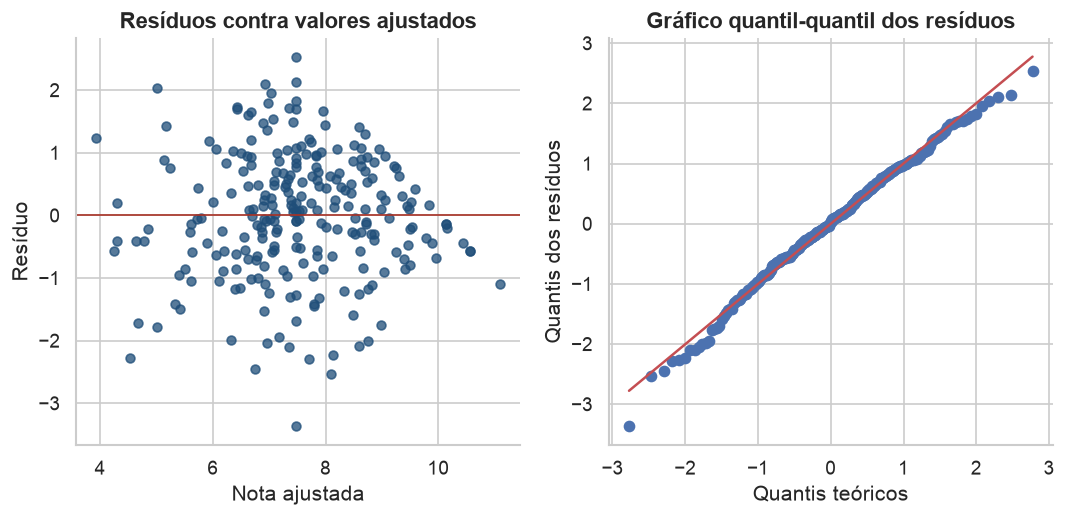

PosixPath('figuras/07_residuos_ols.png')

In [20]:
y = dispersao["nota"]
x_simples = sm.add_constant(dispersao["horas_estudo"])
modelo_simples = sm.OLS(y, x_simples).fit()
print(modelo_simples.summary())

b0 = float(modelo_simples.params["const"])
b1 = float(modelo_simples.params["horas_estudo"])
print(f"Reta: Y_chapeu = {b0:.4f} + {b1:.4f} * horas")
print(f"R2 = {modelo_simples.rsquared:.4f}, R2 ajustado = {modelo_simples.rsquared_adj:.4f}")
print(f"Previsão em 50 horas: {float(modelo_simples.predict([1, 50])[0]):.2f}")

residuos = modelo_simples.resid
ajustados = modelo_simples.fittedvalues
shapiro_res = stats.shapiro(residuos)
jb = sm.stats.jarque_bera(residuos)
bp = het_breuschpagan(residuos, modelo_simples.model.exog)
modelo_robusto = modelo_simples.get_robustcov_results(cov_type="HC3")

print(f"Shapiro-Wilk dos resíduos: W = {shapiro_res.statistic:.4f}, p = {shapiro_res.pvalue:.4f}")
print(f"Jarque-Bera: estatística = {float(jb[0]):.3f}, p = {float(jb[1]):.4f}")
print(f"Breusch-Pagan: LM = {bp[0]:.3f}, p = {bp[1]:.4f}")
print("Intervalo de 95% de b1 com erro padrão clássico:", modelo_simples.conf_int().loc["horas_estudo"].tolist())
print("p de b1 com HC3:", float(modelo_robusto.pvalues[1]))

fig, eixos = plt.subplots(1, 2, figsize=(10.5, 4.4))
eixos[0].scatter(ajustados, residuos, color=AZUL, alpha=0.75, s=28)
eixos[0].axhline(0, color=VERMELHO, lw=1)
eixos[0].set_xlabel("Nota ajustada")
eixos[0].set_ylabel("Resíduo")
eixos[0].set_title("Resíduos contra valores ajustados")
stats.probplot(residuos, dist="norm", plot=eixos[1])
eixos[1].set_title("Gráfico quantil-quantil dos resíduos")
eixos[1].set_xlabel("Quantis teóricos")
eixos[1].set_ylabel("Quantis dos resíduos")
sns.despine(fig)
salvar(fig, "07_residuos_ols.png")

In [21]:
horas_para_nota_6 = (6 - b0) / b1
display(Markdown(
    f"""**Leitura da reta simples.** $\hat{{Y}} = {b0:.3f} + {b1:.3f}\,X$.
Cada hora semanal a mais está associada, em média, a {br(b1, 2)} ponto na nota.
Quatro horas a mais na semana, algo como 50 minutos a mais em cada dia útil, correspondem a cerca de {br(4 * b1, 2)} ponto.
O intercepto {br(b0, 2)} não descreve um aluno que não estuda: esse aluno não existe na amostra, e a reta não foi estimada nessa região.
O R² é {br(modelo_simples.rsquared, 3)}: {br(modelo_simples.rsquared * 100, 1)}% da variância da nota acompanha as horas.
Os outros {br((1 - modelo_simples.rsquared) * 100, 1)}% ficam no resíduo. O desvio padrão residual é {br(np.sqrt(modelo_simples.scale), 2)} ponto,
então a reta localiza o aluno típico e ainda erra por volta de um ponto para mais ou para menos.
A reta cruza a nota 6, corte de aprovação usado na geração do status, perto de {br(horas_para_nota_6, 1)} horas semanais.
Isso é uma média, não uma garantia: com resíduo de um ponto, há aprovados abaixo disso e reprovados acima.
Shapiro-Wilk não rejeita a normalidade dos resíduos (p = {shapiro_res.pvalue:.3f}) e Jarque-Bera concorda (p = {float(jb[1]):.3f}).
Breusch-Pagan rejeita a homocedasticidade a 5% (p = {bp[1]:.3f}). A nuvem de resíduos abre um pouco ao longo da reta.
O coeficiente de horas continua altamente significativo com erro padrão HC3, então a conclusão sobre a associação não depende do erro padrão clássico.
Em 50 horas a equação prevê nota {br(float(modelo_simples.predict([1, 50])[0]), 1)}, o que é impossível numa escala de 0 a 10.
Cinquenta horas está muito além do máximo observado, perto de {br(dispersao['horas_estudo'].max(), 0)} horas, e a nota ainda esbarra no teto 10.
Usar a reta nessa região é extrapolação. A equação vale dentro da faixa observada."""
))

<>:17: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:17: SyntaxWarning: "\," is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\,"? A raw string is also an option.
<>:17: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:17: SyntaxWarning: "\," is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\,"? A raw string is also an option.
/var/folders/xc/6kzclg_15yb5rjwr650_mf_00000gp/T/ipykernel_46170/2453137280.py:17: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
  Usar a reta nessa região é extrapolação. A equação vale dentro da faixa observada."""
/var/folders/xc/6kzclg_15yb5rjwr650_mf_00000gp/T/ipykernel_46170/2

**Leitura da reta simples.** $\hat{Y} = 3.598 + 0.324\,X$.
Cada hora semanal a mais está associada, em média, a 0,32 ponto na nota.
Quatro horas a mais na semana, algo como 50 minutos a mais em cada dia útil, correspondem a cerca de 1,30 ponto.
O intercepto 3,60 não descreve um aluno que não estuda: esse aluno não existe na amostra, e a reta não foi estimada nessa região.
O R² é 0,629: 62,9% da variância da nota acompanha as horas.
Os outros 37,1% ficam no resíduo. O desvio padrão residual é 1,00 ponto,
então a reta localiza o aluno típico e ainda erra por volta de um ponto para mais ou para menos.
A reta cruza a nota 6, corte de aprovação usado na geração do status, perto de 7,4 horas semanais.
Isso é uma média, não uma garantia: com resíduo de um ponto, há aprovados abaixo disso e reprovados acima.
Shapiro-Wilk não rejeita a normalidade dos resíduos (p = 0.324) e Jarque-Bera concorda (p = 0.157).
Breusch-Pagan rejeita a homocedasticidade a 5% (p = 0.031). A nuvem de resíduos abre um pouco ao longo da reta.
O coeficiente de horas continua altamente significativo com erro padrão HC3, então a conclusão sobre a associação não depende do erro padrão clássico.
Em 50 horas a equação prevê nota 19,8, o que é impossível numa escala de 0 a 10.
Cinquenta horas está muito além do máximo observado, perto de 23 horas, e a nota ainda esbarra no teto 10.
Usar a reta nessa região é extrapolação. A equação vale dentro da faixa observada.

### 5.2 Regressão linear múltipla

O segundo regressor é a taxa de conclusão já na escala decimal [0, 1]. O interesse é o $R^2$ ajustado e o que acontece com o coeficiente das horas quando a conclusão entra no modelo.

Se a conclusão afeta a nota e também está ligada às horas, deixá-la de fora empurra parte desse efeito para $b_1$. O sinal esperado desse viés é positivo: horas e conclusão se correlacionam, e conclusão e nota também. Controlar a conclusão deve reduzir o coeficiente das horas, não porque horas tenham deixado de importar, e sim porque o modelo simples misturava os dois caminhos.

O fator de inflação da variância (VIF) verifica se as duas variáveis estão coladas demais para serem separadas.

In [22]:
x_multiplo = sm.add_constant(dispersao[["horas_estudo", "taxa_conclusao"]])
modelo_multiplo = sm.OLS(y, x_multiplo).fit()
print(modelo_multiplo.summary())

vif = pd.DataFrame({
    "variavel": ["horas_estudo", "taxa_conclusao"],
    "VIF": [
        variance_inflation_factor(x_multiplo.values, 1),
        variance_inflation_factor(x_multiplo.values, 2),
    ],
})
display(vif.round(3))

comparacao = pd.DataFrame({
    "simples": [modelo_simples.params["const"], modelo_simples.params["horas_estudo"], np.nan,
                modelo_simples.rsquared, modelo_simples.rsquared_adj],
    "múltiplo": [modelo_multiplo.params["const"], modelo_multiplo.params["horas_estudo"],
                 modelo_multiplo.params["taxa_conclusao"],
                 modelo_multiplo.rsquared, modelo_multiplo.rsquared_adj],
}, index=["intercepto", "horas", "taxa de conclusão", "R2", "R2 ajustado"])
display(comparacao.round(4))

# Casos completos: sem hora imputada e sem nota inválida. Mede se a mediana inventou a reta.
completos = df.loc[~df["hora_imputada"] & ~df["nota_invalida"]]
modelo_cc = sm.OLS(
    completos["nota"], sm.add_constant(completos["horas_estudo"])
).fit()
print(
    f"Casos completos (n = {int(modelo_cc.nobs)}): "
    f"b1 = {modelo_cc.params['horas_estudo']:.4f}, R2 = {modelo_cc.rsquared:.4f}"
)
print(
    f"Com imputação (n = {int(modelo_simples.nobs)}): "
    f"b1 = {b1:.4f}, R2 = {modelo_simples.rsquared:.4f}"
)

b2 = float(modelo_multiplo.params["taxa_conclusao"])
b1_multiplo = float(modelo_multiplo.params["horas_estudo"])

                            OLS Regression Results                            
Dep. Variable:                   nota   R-squared:                       0.762
Model:                            OLS   Adj. R-squared:                  0.760
Method:                 Least Squares   F-statistic:                     394.7
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           1.69e-77
Time:                        09:19:16   Log-Likelihood:                -296.94
No. Observations:                 249   AIC:                             599.9
Df Residuals:                     246   BIC:                             610.4
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              1.8064      0.222      8.

,variavel,VIF
0,horas_estudo,1.561
1,taxa_conclusao,1.561


,simples,múltiplo
intercepto,3.5977,1.8064
horas,0.3239,0.2124
taxa de conclusão,NaN,4.1733
R2,0.6294,0.7624
R2 ajustado,0.6279,0.7605


Casos completos (n = 238): b1 = 0.3241, R2 = 0.6653
Com imputação (n = 249): b1 = 0.3239, R2 = 0.6294


In [23]:
display(Markdown(
    f"""**Leitura do modelo múltiplo.** $\hat{{Y}} = {modelo_multiplo.params['const']:.3f} + {b1_multiplo:.3f}\,X_1 + {b2:.3f}\,X_2$,
com $X_2$ na escala de 0 a 1.
Dez pontos percentuais a mais de conclusão ({br(0.10, 2)} na escala decimal) estão associados a {br(0.10 * b2, 2)} ponto na nota.
O R² ajustado sobe de {br(modelo_simples.rsquared_adj, 3)} para {br(modelo_multiplo.rsquared_adj, 3)}.
A conclusão acrescenta informação que as horas não carregavam sozinhas, e o ganho paga o parâmetro extra.
O coeficiente das horas cai de {br(b1, 3)} para {br(b1_multiplo, 3)}. O modelo simples estava inflado:
parte do que ele atribuía às horas era conclusão de módulo, que caminha junto com o tempo de estudo (r = {pearson_horas_taxa.statistic:.2f}).
Os dois coeficientes continuam significativos. Horas não eram um disfarce da taxa de conclusão, nem o contrário.
O VIF fica perto de {br(float(vif['VIF'].max()), 2)}, longe de uma colinearidade que impeça a leitura.
A reta estimada só com quem tem hora observada é praticamente a mesma da reta com imputação
(b1 de {br(float(modelo_cc.params['horas_estudo']), 3)} contra {br(b1, 3)}). A mediana não fabricou o resultado.
Ainda faltam variáveis: turma, dificuldade do curso e conhecimento prévio não estão na base. O controle da taxa de conclusão reduz um viés, não esgota os demais."""
))

<>:13: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:13: SyntaxWarning: "\," is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\,"? A raw string is also an option.
<>:13: SyntaxWarning: "\," is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\,"? A raw string is also an option.
<>:13: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:13: SyntaxWarning: "\," is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\,"? A raw string is also an option.
<>:13: SyntaxWarning: "\," is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\,"? A raw string is also an option.
/var/folders/xc/6kzclg_15yb5rjwr650_mf_00000gp/T/ipykernel_46170/2026574201.

**Leitura do modelo múltiplo.** $\hat{Y} = 1.806 + 0.212\,X_1 + 4.173\,X_2$,
com $X_2$ na escala de 0 a 1.
Dez pontos percentuais a mais de conclusão (0,10 na escala decimal) estão associados a 0,42 ponto na nota.
O R² ajustado sobe de 0,628 para 0,760.
A conclusão acrescenta informação que as horas não carregavam sozinhas, e o ganho paga o parâmetro extra.
O coeficiente das horas cai de 0,324 para 0,212. O modelo simples estava inflado:
parte do que ele atribuía às horas era conclusão de módulo, que caminha junto com o tempo de estudo (r = 0.60).
Os dois coeficientes continuam significativos. Horas não eram um disfarce da taxa de conclusão, nem o contrário.
O VIF fica perto de 1,56, longe de uma colinearidade que impeça a leitura.
A reta estimada só com quem tem hora observada é praticamente a mesma da reta com imputação
(b1 de 0,324 contra 0,324). A mediana não fabricou o resultado.
Ainda faltam variáveis: turma, dificuldade do curso e conhecimento prévio não estão na base. O controle da taxa de conclusão reduz um viés, não esgota os demais.

### 5.3 Intervalo de confiança para a média das notas

Com $\sigma$ desconhecido e $n$ finito, o intervalo de 95% para a média populacional usa a distribuição t de Student:

$$\bar{x} \pm t_{n-1,\,0{,}975}\,\dfrac{s}{\sqrt{n}}$$

A série é a nota saneada. O intervalo fala da média, não da nota de um aluno específico. Pelo teorema central do limite, a média amostral com $n = 249$ se aproxima da normal mesmo que a nota individual não seja normal, como o Shapiro-Wilk já mostrou.

In [24]:
n_ic = len(nota)
media_ic = float(nota.mean())
erro_padrao = float(stats.sem(nota, ddof=1))
t_crit_ic = float(stats.t.ppf(0.975, n_ic - 1))
limite_inf = media_ic - t_crit_ic * erro_padrao
limite_sup = media_ic + t_crit_ic * erro_padrao
ic_scipy = stats.t.interval(0.95, n_ic - 1, loc=media_ic, scale=erro_padrao)

print(f"n = {n_ic}, média = {media_ic:.4f}, s = {nota.std(ddof=1):.4f}")
print(f"erro padrão = {erro_padrao:.4f}, t crítico = {t_crit_ic:.4f}")
print(f"IC 95% manual = [{limite_inf:.4f}, {limite_sup:.4f}]")
print(f"IC 95% SciPy  = [{ic_scipy[0]:.4f}, {ic_scipy[1]:.4f}]")

n = 249, média = 7.5156, s = 1.6391
erro padrão = 0.1039, t crítico = 1.9696
IC 95% manual = [7.3110, 7.7202]
IC 95% SciPy  = [7.3110, 7.7202]


## Módulo VI — Síntese para a gestão

A faixa de horas abaixo foi cortada ao redor do ponto em que a reta simples cruza a nota 6. Não é um limiar mágico. É a região em que o aluno típico deixa de ter média prevista acima do corte de aprovação. O gráfico mostra por que o acompanhamento de horas importa mais, nesta base, do que a comparação entre polos.

,alunos,nota_media,aprovacao
faixa,,,
até 8 h,33,5.06,21.2
8 a 12 h,101,7.12,82.2
12 a 16 h,75,8.16,96.0
acima de 16 h,40,9.33,100.0


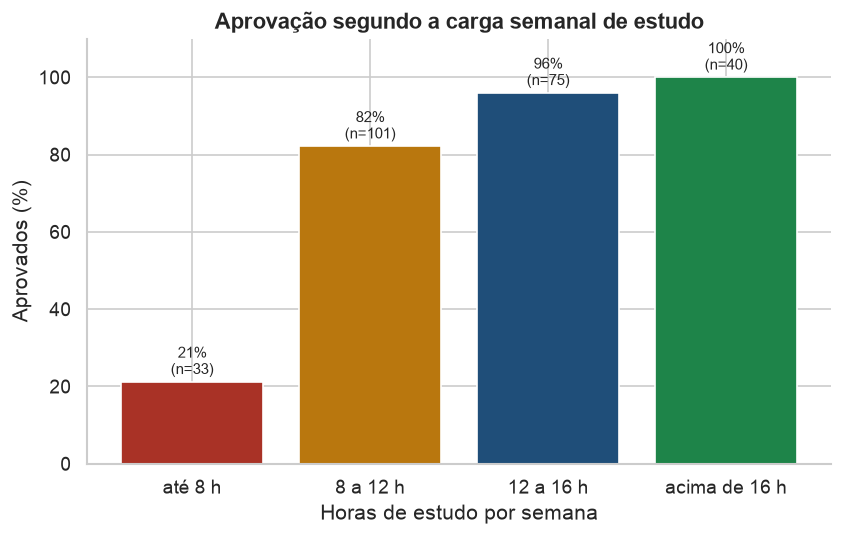

**Síntese.** Dos 47 reprovados com nota válida, 26 estudam até 8 horas por semana.
Esse grupo tem 33 alunos, 13,3% da base com nota válida,
e concentra 55,3% das reprovações.
Acima de 16 horas, a aprovação observada nesta amostra é de 100%.
O intervalo de 95% para a média das notas vai de 7,31 a 7,72.
A turma, como conjunto, está confortavelmente acima de 6. O problema não é a média. É a cauda de quem estuda pouco.
O detalhamento para a coordenação está no relatório executivo.

In [25]:
faixas = pd.cut(
    dispersao["horas_estudo"],
    bins=[0, 8, 12, 16, 40],
    labels=["até 8 h", "8 a 12 h", "12 a 16 h", "acima de 16 h"],
)
painel = dispersao.copy()
painel["faixa"] = faixas
painel["aprovado"] = df.loc[painel.index, "aprovado"].eq("Sim")

resumo_faixas = painel.groupby("faixa", observed=True).agg(
    alunos=("nota", "size"),
    nota_media=("nota", "mean"),
    aprovacao=("aprovado", "mean"),
)
display(resumo_faixas.assign(aprovacao=lambda t: (t["aprovacao"] * 100).round(1), nota_media=lambda t: t["nota_media"].round(2)))

reprovados = int((~painel["aprovado"]).sum())
reprovados_baixa_carga = int((~painel["aprovado"] & (painel["horas_estudo"] <= 8)).sum())
alunos_baixa_carga = int((painel["horas_estudo"] <= 8).sum())

fig, ax = plt.subplots(figsize=(8, 4.6))
valores = resumo_faixas["aprovacao"] * 100
barras = ax.bar(valores.index.astype(str), valores.values, color=[VERMELHO, "#B9770E", AZUL, VERDE])
ax.set_ylim(0, 110)
ax.set_ylabel("Aprovados (%)")
ax.set_xlabel("Horas de estudo por semana")
ax.set_title("Aprovação segundo a carga semanal de estudo")
for barra, pct, qtd in zip(barras, valores.values, resumo_faixas["alunos"]):
    ax.text(barra.get_x() + barra.get_width() / 2, pct + 2, f"{pct:.0f}%\n(n={qtd})", ha="center", fontsize=9)
sns.despine()
salvar(fig, "08_aprovacao_por_faixa_horas.png")

colunas_tratadas = [
    "id_aluno", "nivel_ensino", "regiao_campus", "horas_estudo", "hora_imputada",
    "taxa_conclusao_pct", "taxa_conclusao", "nota_exame_final", "nota", "nota_invalida", "aprovado",
]
df[colunas_tratadas].to_csv("dados/edutech_performance_tratada.csv", index=False)

display(Markdown(
    f"""**Síntese.** Dos {reprovados} reprovados com nota válida, {reprovados_baixa_carga} estudam até 8 horas por semana.
Esse grupo tem {alunos_baixa_carga} alunos, {br(alunos_baixa_carga / len(painel) * 100, 1)}% da base com nota válida,
e concentra {br(reprovados_baixa_carga / reprovados * 100, 1)}% das reprovações.
Acima de 16 horas, a aprovação observada nesta amostra é de 100%.
O intervalo de 95% para a média das notas vai de {br(limite_inf, 2)} a {br(limite_sup, 2)}.
A turma, como conjunto, está confortavelmente acima de 6. O problema não é a média. É a cauda de quem estuda pouco.
O detalhamento para a coordenação está no relatório executivo."""
))

## Limites desta análise

- A base é didática, com anomalias inseridas de propósito. Os números descrevem estes 250 registros.
- Onze cargas horárias foram imputadas pela mediana. A comparação com os casos completos mostrou que a reta não depende dessa escolha, mas a hora verdadeira desses alunos não foi recuperada.
- A nota −2,5 foi excluída das contas numéricas. O status de aprovação dessa linha foi mantido.
- Associação não é efeito de uma intervenção. O modelo múltiplo controla a taxa de conclusão e ainda deixa de fora turma, dificuldade e repertório do aluno.
- A nota está censurada em 10. Previsões lineares perto do topo, e qualquer previsão fora da faixa de horas observada, não devem ser usadas.
- Os testes que não rejeitaram $H_0$ não autorizam a frase "não existe diferença". Autorizam a frase "esta amostra não mostrou diferença além do acaso".